Total de órdenes analizadas: 95,353


,order_id,customer_id,order_status,purchase_date,macro_category,category_english,total_items,total_price,total_freight,primary_payment_type,max_installments,total_payment_value,payment_segment,hours_to_carrier,delivery_delay_days,dispatch_sla_status,avg_review_score
0,cd3b8574c82b42fc8129f6d502690c3e,7812fcebfc5e8065d31e1bb5f0017dae,delivered,2016-10-03,"Fashion, Beauty & Watches",Fashion Shoes,1,29.99,10.96,credit_card,4,40.95,Credit Card (3+ Installments),96,-40.0,Slow Dispatch (> 48h),5.0
1,79ffdd52a918bbe867895a4b183d6457,f9808148a262b51d20e2d777eee6676c,delivered,2016-10-04,Tech & Electronics,Air Conditioning,1,299.99,19.01,credit_card,10,319.00,Credit Card (3+ Installments),505,-29.0,Slow Dispatch (> 48h),1.0
2,7a7d2c889e27d93b2005462a8788e168,88927ff4f54b497957d9947e926ec6fe,delivered,2016-10-05,"Fashion, Beauty & Watches",Fashion Male Clothing,1,24.90,10.96,credit_card,3,35.86,Credit Card (3+ Installments),574,-25.0,Slow Dispatch (> 48h),1.0



--- RESUMEN POR SEGMENTO DE PAGO (AOV) ---


,payment_segment,total_orders,avg_ticket_value,median_ticket_value,avg_review_score
1,Credit Card (3+ Installments),36733,218.95,146.68,4.11
2,Other Payment Methods (Boleto/Voucher/Debit),24004,142.30,92.57,4.15
0,Credit Card (1-2 Installments),34616,109.72,81.52,4.20



--- IMPACTO DEL DESPACHO (>48H) EN LA CALIFICACIÓN ---


,payment_segment,dispatch_sla_status,orders_count,avg_review,pct_negative_reviews
0,Credit Card (1-2 Installments),Fast Dispatch (<= 48h),18954,4.31,9.51
1,Credit Card (1-2 Installments),Slow Dispatch (> 48h),15662,4.08,13.98
2,Credit Card (3+ Installments),Fast Dispatch (<= 48h),19277,4.22,11.54
3,Credit Card (3+ Installments),Slow Dispatch (> 48h),17456,3.99,16.66
4,Other Payment Methods (Boleto/Voucher/Debit),Fast Dispatch (<= 48h),13451,4.25,10.22
5,Other Payment Methods (Boleto/Voucher/Debit),Slow Dispatch (> 48h),10553,4.03,15.41


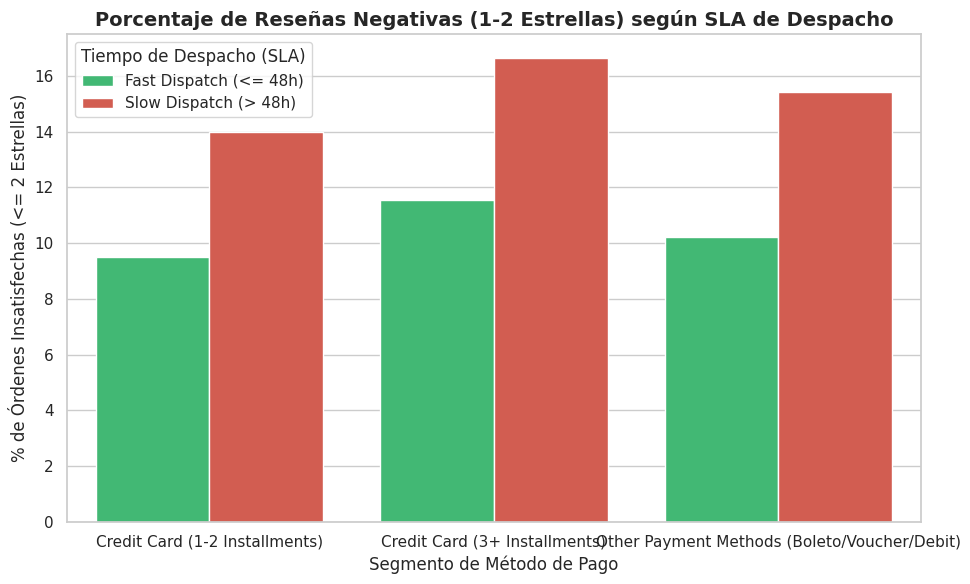


--- AUDITORÍA DE OUTLIERS LOGÍSTICOS (MÉTODO IQR) ---
Umbral de sobrecosto de flete (Q3 + 1.5*IQR): R$ 39.27
Órdenes con sobrecosto detectadas: 9,569 (10.04% del total)


/tmp/ipykernel_1079/1474374892.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


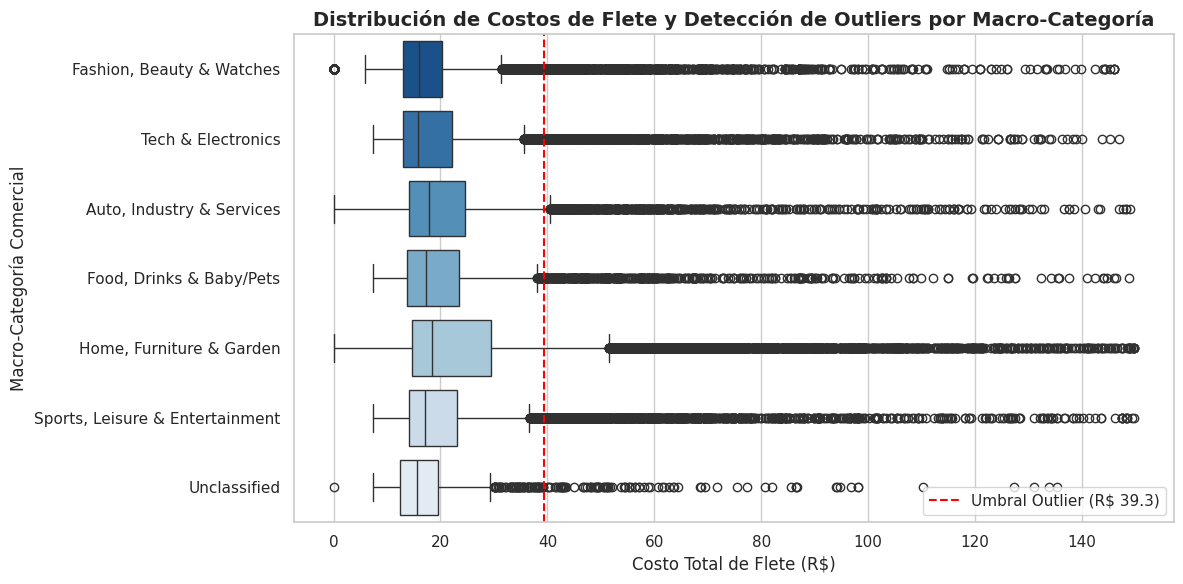

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Configuración visual profesional para el portafolio
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (11, 6)

# 1. Cargar el dataset maestro exportado de BigQuery
# (Asegúrate de que el nombre coincida con tu archivo subido a Colab)
df = pd.read_csv('/content/drive/MyDrive/master_orders_analytics.csv')

print(f"Total de órdenes analizadas: {df.shape[0]:,}")
display(df.head(3))

# ---------------------------------------------------------
# 2. PRUEBA DE HIPÓTESIS PARTE 1: Impacto de Cuotas en el Ticket Promedio (AOV)
# ---------------------------------------------------------
aov_summary = df.groupby('payment_segment').agg(
    total_orders=('order_id', 'count'),
    avg_ticket_value=('total_payment_value', 'mean'),
    median_ticket_value=('total_payment_value', 'median'),
    avg_review_score=('avg_review_score', 'mean')
).reset_index().sort_values(by='avg_ticket_value', ascending=False)

print("\n--- RESUMEN POR SEGMENTO DE PAGO (AOV) ---")
display(aov_summary.round(2))

# ---------------------------------------------------------
# 3. PRUEBA DE HIPÓTESIS PARTE 2: Impacto del SLA de Despacho (>48h) en Satisfacción
# ---------------------------------------------------------
sla_impact = df.groupby(['payment_segment', 'dispatch_sla_status']).agg(
    orders_count=('order_id', 'count'),
    avg_review=('avg_review_score', 'mean'),
    pct_negative_reviews=('avg_review_score', lambda x: (x <= 2).mean() * 100)
).reset_index()

print("\n--- IMPACTO DEL DESPACHO (>48H) EN LA CALIFICACIÓN ---")
display(sla_impact.round(2))

# Gráfico 1: Caída de Satisfacción por Segmento de Pago y Velocidad de Despacho
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=sla_impact,
    x='payment_segment',
    y='pct_negative_reviews',
    hue='dispatch_sla_status',
    palette=['#2ecc71', '#e74c3c']
)
plt.title('Porcentaje de Reseñas Negativas (1-2 Estrellas) según SLA de Despacho', fontsize=14, fontweight='bold')
plt.xlabel('Segmento de Método de Pago', fontsize=12)
plt.ylabel('% de Órdenes Insatisfechas (<= 2 Estrellas)', fontsize=12)
plt.legend(title='Tiempo de Despacho (SLA)')
plt.tight_layout()
plt.savefig('1_sla_satisfaction_impact.png', dpi=300)
plt.show()

# ---------------------------------------------------------
# 4. AUDITORÍA DE CONTROL DE GESTIÓN: Detección de Outliers en Fletes (IQR)
# ---------------------------------------------------------
# Calculamos qué porcentaje representa el flete sobre el precio del producto
df['freight_to_price_ratio'] = (df['total_freight'] / df['total_price']) * 100

Q1 = df['total_freight'].quantile(0.25)
Q3 = df['total_freight'].quantile(0.75)
IQR = Q3 - Q1
outlier_threshold = Q3 + 1.5 * IQR

outliers_df = df[df['total_freight'] > outlier_threshold]
print(f"\n--- AUDITORÍA DE OUTLIERS LOGÍSTICOS (MÉTODO IQR) ---")
print(f"Umbral de sobrecosto de flete (Q3 + 1.5*IQR): R$ {outlier_threshold:.2f}")
print(f"Órdenes con sobrecosto detectadas: {len(outliers_df):,} ({len(outliers_df)/len(df)*100:.2f}% del total)")

# Gráfico 2: Boxplot de Costos de Flete por Macro-Categoría (Filtrando extremos visuales para claridad)
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df[df['total_freight'] <= 150],
    x='total_freight',
    y='macro_category',
    palette='Blues_r'
)
plt.axvline(outlier_threshold, color='red', linestyle='--', label=f'Umbral Outlier (R$ {outlier_threshold:.1f})')
plt.title('Distribución de Costos de Flete y Detección de Outliers por Macro-Categoría', fontsize=14, fontweight='bold')
plt.xlabel('Costo Total de Flete (R$)', fontsize=12)
plt.ylabel('Macro-Categoría Comercial', fontsize=12)
plt.legend()
plt.tight_layout()
plt.savefig('2_freight_outliers_boxplot.png', dpi=300)
plt.show()